COMMON SETUP

In [10]:
# ============================================================
# COMMON SETUP
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import (
    preprocess_input, decode_predictions
)
from tensorflow.keras.utils import load_img, img_to_array
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, GlobalAveragePooling2D,
    Embedding, LSTM
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

# Configure paths based on your lab environment setup
DATASET_DIR = "imagenet_subset" # Path to the folder containing image subfolders
MAPPING_FILE_PATH = "words.txt" # Path to your class mapping txt file
IMG_SIZE = (224, 224)

LOAD LOCAL DATASET AND LABELS

In [11]:
# Load human-readable label mapping from words.txt if available
label_mapping = {}
if os.path.exists(MAPPING_FILE_PATH):
    with open(MAPPING_FILE_PATH, "r") as f:
        for line in f:
            parts = line.strip().split("\t")
            if len(parts) >= 2:
                label_mapping[parts[0]] = parts[1]
else:
    print(f"Warning: Mapping file not found at '{MAPPING_FILE_PATH}'. Folder names will be used as classes.")

image_paths = []
labels = []

if not os.path.exists(DATASET_DIR):
    raise FileNotFoundError(
        f"Dataset directory not found at '{DATASET_DIR}'. "
        "Please set DATASET_DIR to the correct path in the Common Setup cell."
    )

for class_name in sorted(os.listdir(DATASET_DIR)):
    class_dir = os.path.join(DATASET_DIR, class_name)

    if not os.path.isdir(class_dir):
        continue

    for file in os.listdir(class_dir):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(class_dir, file))
            # Use mapped name if available, otherwise fallback to the directory name
            friendly_name = label_mapping.get(class_name, class_name)
            labels.append(friendly_name)

if not image_paths:
    raise ValueError(
        f"No images found in '{DATASET_DIR}'. "
        "Expected one subfolder per class, containing JPG/PNG images."
    )

encoder = LabelEncoder()
y = encoder.fit_transform(labels)
class_names = encoder.classes_

print("Images found:", len(image_paths))
print("Classes:", class_names)

X_train_paths, X_test_paths, y_train, y_test = train_test_split(
    image_paths,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

def load_preprocess_image(path):
    """Load one local image and preprocess it for ResNet50."""
    image = load_img(path, target_size=IMG_SIZE)
    image = img_to_array(image)
    image = np.expand_dims(image, axis=0)
    image = preprocess_input(image)
    return image

# Display an original image
image = load_img(X_train_paths[0], target_size=IMG_SIZE)
plt.imshow(image)
plt.title(class_names[y_train[0]])
plt.axis("off")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'imagenet_subset'

EXPERIMENT 1

In [12]:
# include_top=True retains the original ImageNet 1000-class head.
model = ResNet50(
    weights="imagenet",
    include_top=True
)

image = load_preprocess_image(X_test_paths[0])
predictions = model.predict(image, verbose=0)

print("Prediction shape:", predictions.shape)

top5 = decode_predictions(predictions, top=5)[0]

for _, name, probability in top5:
    print(name, f"{probability * 100:.2f}%")


102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


NameError: name 'load_preprocess_image' is not defined

**EXPERIMENT 2**

In [13]:
# include_top=False exposes the convolutional feature-extraction layers.
cnn_model = ResNet50(
    weights="imagenet",
    include_top=False
)
cnn_model.trainable = False

# Print available layer names/shapes if you need to choose other layers.
# for i, layer in enumerate(cnn_model.layers):
#     print(i, layer.name, layer.output.shape)

layer_names = [
    "conv1_relu",
    "conv3_block4_out",
    "conv5_block3_out"
]

for name in layer_names:
    print(name, cnn_model.get_layer(name).output.shape)

image = load_preprocess_image(X_test_paths[0])

outputs = [
    cnn_model.get_layer(name).output
    for name in layer_names
]

feature_model = Model(
    inputs=cnn_model.input,
    outputs=outputs
)

feature_maps = feature_model.predict(image, verbose=0)

# Display one feature map from each selected layer.
for name, feature in zip(layer_names, feature_maps):
    print(name, "feature shape:", feature.shape)

    plt.figure(figsize=(5, 5))
    plt.imshow(feature[0, :, :, 0], cmap="viridis")
    plt.title(name)
    plt.axis("off")
    plt.show()

# Visualize learned filters from the first convolutional layer.
layer = cnn_model.get_layer("conv1_conv")
filters, biases = layer.get_weights()

print("Filter shape:", filters.shape)
print("Bias shape:", biases.shape)

plt.figure(figsize=(12, 6))

for i in range(8):
    f = filters[:, :, :, i]
    f = (f - f.min()) / (f.max() - f.min() + 1e-8)

    plt.subplot(2, 4, i + 1)
    plt.imshow(f)
    plt.title(f"Filter {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
conv1_relu (None, None, None, 64)
conv3_block4_out (None, None, None, 512)
conv5_block3_out (None, None, None, 2048)


NameError: name 'load_preprocess_image' is not defined

EXPERIMENT 3

In [3]:
base_model = ResNet50(
    weights="imagenet",
    include_top=False
)
base_model.trainable = False

feature_extractor = Model(
    inputs=base_model.input,
    outputs=GlobalAveragePooling2D()(base_model.output)
)


def extract_features(paths):
    """Extract one pooled ResNet50 feature vector per local image."""
    features = []

    for path in paths:
        image = load_preprocess_image(path)
        feature = feature_extractor.predict(image, verbose=0)
        features.append(feature[0])

    return np.array(features, dtype=np.float32)


X_train_features = extract_features(X_train_paths)
X_test_features = extract_features(X_test_paths)

print("Training features:", X_train_features.shape)
print("Testing features:", X_test_features.shape)

# ResNet50 with GlobalAveragePooling2D produces 2048 features.
num_classes = len(class_names)

classifier = tf.keras.Sequential([
    Input(shape=(2048,)),
    Dense(256, activation="relu"),
    Dropout(0.4),
    Dense(num_classes, activation="softmax")
])

classifier.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = classifier.fit(
    X_train_features,
    y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=32
)

# Plot training and validation accuracy.
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Predict test classes.
probabilities = classifier.predict(X_test_features, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print("Actual:", y_test[:10])
print("Predicted:", y_pred[:10])

# Calculate evaluation metrics.
print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(
          y_test, y_pred,
          average="weighted", zero_division=0
      ))

print("Recall:",
      recall_score(
          y_test, y_pred,
          average="weighted", zero_division=0
      ))

print("F1 Score:",
      f1_score(
          y_test, y_pred,
          average="weighted", zero_division=0
      ))

# Display confusion matrix.
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(xticks_rotation=90)
plt.tight_layout()
plt.show()


Found 9469 files belonging to 10 classes.
Found 3925 files belonging to 10 classes.
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Feature map shape: (None, None, None, 512)
Feature vector size: 512
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - accuracy: 0.0850 - loss: 8.3140
Confusion Matrix:
[[3 2 0 1 0 0 0 0 0 1]
 [0 0 1 2 0 1 2 0 0 0]
 [0 0 0 0 0 1 3 0 0 0]
 [1 0 1 0 0 0 2 0 0 0]
 [2 0 1 1 0 0 0 0 0 0]
 [0 0 1 0 0 3 0 0 0 0]
 [0 0 0 2 0 0 1 1 0 0]
 [2 0 1 0 0 6 0 1 0 0]
 [3 0 0 0 0 0 0 3 0 0]
 [4 0 0 0 5 1 1 0 0 0]]

Accuracy, Precision, Recall and F1:
              precision    recall  f1-score   support

           0       0.20      0.43      0.27         7
           1       0.00      0.00      0.00         6
           2       0.00      0.00      0.00         4
           3       0.00      0.00      0.00         4
           4       0.00      0.00      0.00         4
           5       0.25      0.75      0.38         4
           6       0.11      0.25      0.15         4
   

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


experiment 4 rizz

In [8]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

# Download Imagenette
url = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz"

archive = tf.keras.utils.get_file(
    "imagenette2-160.tgz",
    url,
    untar=True
)

# Load training images
train = tf.keras.utils.image_dataset_from_directory(
    archive + "/imagenette2-160/train",
    image_size=(224,224),
    batch_size=20,
    shuffle=False
)

test = tf.keras.utils.image_dataset_from_directory(
    archive + "/imagenette2-160/val",
    image_size=(224,224),
    batch_size=20,
    shuffle=False
)

classes = train.class_names

train = train.take(10)
test = test.take(3)

cnn = VGG16(
    weights="imagenet",
    include_top=False,
    pooling="avg"
)

train_images = np.concatenate([x.numpy() for x,y in train])
train_labels = np.concatenate([y.numpy() for x,y in train])

test_images = np.concatenate([x.numpy() for x,y in test])
test_labels = np.concatenate([y.numpy() for x,y in test])

train_features = cnn.predict(preprocess_input(train_images))
test_features = cnn.predict(preprocess_input(test_images))

print("CNN Feature Vector:", train_features.shape)

X = train_features.reshape(
    train_features.shape[0],
    1,
    train_features.shape[1]
)

model = tf.keras.Sequential([
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(len(classes), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(X, train_labels, epochs=10)

test_X = test_features.reshape(
    test_features.shape[0],
    1,
    test_features.shape[1]
)

pred = model.predict(test_X)

for i in range(min(5, len(pred))):

    predicted_class = classes[np.argmax(pred[i])]

    expected = "A photo of a " + classes[test_labels[i]] + "."
    generated = "A photo of a " + predicted_class + "."

    print("Expected :", expected)
    print("Generated:", generated)
    print()

Found 9469 files belonging to 10 classes.
Found 3925 files belonging to 10 classes.
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 411ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
CNN Feature Vector: (200, 512)
Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6550 - loss: 1.4995
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.2050 
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0651 
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0327 
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0201 
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.0143 
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.0114 
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0097 
Epoch 9/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0085 
Epoch 10/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0

EXPERIMENT 5 RIZZ

Found 9469 files belonging to 10 classes.
Text: A photo of a n01440764


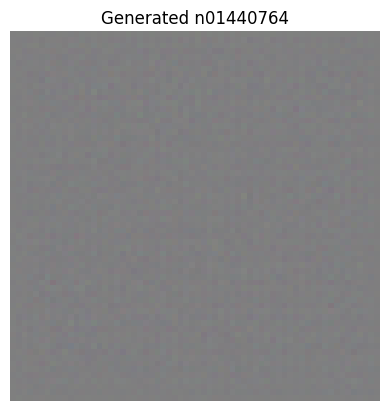

In [9]:
# EX 5 - Conditional GAN

import tensorflow as tf
import matplotlib.pyplot as plt

SIZE = 64
NOISE = 100

# Download Imagenette
url = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz"

archive = tf.keras.utils.get_file(
    "imagenette2-160.tgz",
    url,
    untar=True
)

# Load dataset
data = tf.keras.utils.image_dataset_from_directory(
    archive + "/imagenette2-160/train",
    image_size=(SIZE, SIZE),
    batch_size=32
)

classes = data.class_names
n = len(classes)

# Generator
generator = tf.keras.Sequential([
    tf.keras.layers.Input((NOISE + n,)),
    tf.keras.layers.Dense(8*8*128),
    tf.keras.layers.Reshape((8,8,128)),
    tf.keras.layers.Conv2DTranspose(64, 4, 2, padding="same", activation="relu"),
    tf.keras.layers.Conv2DTranspose(32, 4, 2, padding="same", activation="relu"),
    tf.keras.layers.Conv2DTranspose(3, 4, 2, padding="same", activation="tanh")
])

# Discriminator
discriminator = tf.keras.Sequential([
    tf.keras.layers.Input((SIZE, SIZE, 3+n)),
    tf.keras.layers.Conv2D(64, 4, 2, padding="same"),
    tf.keras.layers.LeakyReLU(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1)
])

# Generate image from text
class_id = 0
text = tf.one_hot([class_id], n)
noise = tf.random.normal((1, NOISE))

generated = generator(
    tf.concat([noise, text], axis=1)
)

image = (generated[0] + 1) / 2

print("Text: A photo of a", classes[class_id])

plt.imshow(image)
plt.title("Generated " + classes[class_id])
plt.axis("off")
plt.show()